# QBUS3340 Task 4: ML demand prediction (ZORA, synthetic data)

One-day-ahead forecasting of daily preform demand.

**Rules followed**
- Chronological train/test split, no shuffling.
- For predicted day *t*, features use only demand up to day *t-1*, the calendar, and `large_customer_project` and `quote_request_index` for day *t* (assumed known, per the brief).
- The `Confirmed_20_Day_Demand` sheet is **not** used for training, tuning or testing. It is only used at the end to illustrate the trained model.

Place `ZORA_synthetic_demand_data.xlsx` in the same folder as this notebook and run all cells.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

XLSX = "ZORA_synthetic_demand_data.xlsx"
Y = "synthetic_demand_preforms"
SEED = 3340
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

hist = pd.read_excel(XLSX, sheet_name="Historical_Demand")
conf = pd.read_excel(XLSX, sheet_name="Confirmed_20_Day_Demand")
print(hist.shape, hist.date.min().date(), "to", hist.date.max().date(), "| missing values:", int(hist.isna().sum().sum()))
hist.head()

(398, 9) 2025-07-01 to 2026-08-02 | missing values: 0


,date,day_index,day_of_week,week_of_year,month,is_weekend,large_customer_project,quote_request_index,synthetic_demand_preforms
0,2025-07-01,1,Tue,27,7,0,0,54,46
1,2025-07-02,2,Wed,27,7,0,0,49,43
2,2025-07-03,3,Thu,27,7,0,0,52,42
3,2025-07-04,4,Fri,27,7,0,0,60,43
4,2025-07-05,5,Sat,27,7,1,0,52,26


## Quick look at the data

Weekday, large-project windows and the quote index all move demand, and demand is strongly autocorrelated. These drive the feature choice below.

In [2]:
print(hist.groupby("day_of_week")[Y].mean().reindex(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]).round(1).to_string())
print()
print(hist.groupby("large_customer_project")[Y].agg(["mean", "count"]).round(1).to_string())
print()
print("corr(demand, quote_request_index):", round(hist[Y].corr(hist["quote_request_index"]), 3))
print("autocorrelation lag1 / lag7:", round(hist[Y].autocorr(1), 3), "/", round(hist[Y].autocorr(7), 3))

day_of_week
Mon    55.5
Tue    54.0
Wed    51.1
Thu    50.6
Fri    47.9
Sat    44.8
Sun    44.1

                        mean  count
large_customer_project             
0                       47.0    329
1                       62.4     69

corr(demand, quote_request_index): 0.537
autocorrelation lag1 / lag7: 0.635 / 0.606


## 4.a Features and chronological split

Features for day *t*: lag-1, lag-2, lag-7 demand, the mean of the previous 7 days, day-of-week dummies (Monday is the reference), the large-project flag, and the quote index for days *t* and *t-1*. Month dummies are left out because one year of data cannot separate seasonality from level shifts.

The first 7 days are dropped (no lag-7). The first 80% of the remaining days are used for training and the last 20% for testing.

In [3]:
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def build_features(df, target):
    f = pd.DataFrame(index=df.index)
    f["lag1"] = df[target].shift(1)
    f["lag2"] = df[target].shift(2)
    f["lag7"] = df[target].shift(7)
    f["roll7"] = df[target].shift(1).rolling(7).mean()      # mean of t-7..t-1, excludes day t
    f["large_project"] = df["large_customer_project"]
    f["quote_idx"] = df["quote_request_index"]
    f["quote_idx_lag1"] = df["quote_request_index"].shift(1)
    for d in DOW[1:]:
        f["dow_" + d] = (df["day_of_week"] == d).astype(int)
    return f

h = hist[["date", "day_of_week", "large_customer_project", "quote_request_index", Y]].copy()
feat_h = build_features(h, Y)
ok = feat_h.notna().all(axis=1)
h, feat_h = h[ok].reset_index(drop=True), feat_h[ok].reset_index(drop=True)

n = len(h)
n_train = int(round(0.8 * n))
tr, te = np.arange(n_train), np.arange(n_train, n)
Xtr, ytr = feat_h.iloc[tr], h[Y].iloc[tr]
Xte, yte = feat_h.iloc[te], h[Y].iloc[te]
print(f"usable rows {n} | train {len(tr)} ({h.date[tr[0]].date()} to {h.date[tr[-1]].date()})"
      f" | test {len(te)} ({h.date[te[0]].date()} to {h.date[te[-1]].date()})")

usable rows 391 | train 313 (2025-07-08 to 2026-05-16) | test 78 (2026-05-17 to 2026-08-02)


### Baselines and ML models

- Baselines: naive (yesterday), seasonal naive (same weekday last week), 7-day moving average.
- ML: OLS linear regression, ridge (penalty chosen by expanding-window cross-validation **inside the training block only**), and a shallow gradient boosting model as a non-linear check.

In [4]:
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return dict(MAE=mean_absolute_error(y, p),
                RMSE=float(np.sqrt(mean_squared_error(y, p))),
                MAPE_pct=100 * np.mean(np.abs(y - p) / y),
                Bias=np.mean(p - y))

preds = {}
preds["Naive (yesterday)"] = Xte["lag1"].values
preds["Seasonal naive (same weekday last week)"] = Xte["lag7"].values
preds["7-day moving average"] = Xte["roll7"].values

tscv = TimeSeriesSplit(n_splits=5)
best_alpha, best_cv = None, np.inf
for a in [0.01, 0.1, 1, 3, 10, 30, 100]:
    errs = []
    for a_idx, b_idx in tscv.split(Xtr):
        m = Ridge(alpha=a).fit(Xtr.iloc[a_idx], ytr.iloc[a_idx])
        errs.append(mean_absolute_error(ytr.iloc[b_idx], m.predict(Xtr.iloc[b_idx])))
    if np.mean(errs) < best_cv:
        best_alpha, best_cv = a, np.mean(errs)
print("Ridge alpha chosen by time-series CV on train:", best_alpha)

ols = LinearRegression().fit(Xtr, ytr)
ridge = Ridge(alpha=best_alpha).fit(Xtr, ytr)
gbr = GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05,
                                subsample=0.8, random_state=SEED).fit(Xtr, ytr)
preds["Linear regression (OLS)"] = ols.predict(Xte)
preds[f"Ridge regression (alpha={best_alpha})"] = ridge.predict(Xte)
preds["Gradient boosting (depth 2)"] = gbr.predict(Xte)

Ridge alpha chosen by time-series CV on train: 0.01


### One-day-ahead test metrics

Bias is predicted minus actual, so a negative value means under-forecasting.

In [5]:
res = pd.DataFrame({k: metrics(yte, v) for k, v in preds.items()}).T.round(2)
res

,MAE,RMSE,MAPE_pct,Bias
Naive (yesterday),7.13,8.78,13.00,0.41
Seasonal naive (same weekday last week),7.74,9.62,13.92,0.79
7-day moving average,6.10,7.56,11.29,0.76
Linear regression (OLS),4.72,5.78,8.34,-0.99
Ridge regression (alpha=0.01),4.71,5.78,8.34,-0.99
Gradient boosting (depth 2),5.29,6.63,9.40,-1.46


In [6]:
coef = pd.Series(ols.coef_, index=Xtr.columns).round(3)
coef["intercept"] = round(ols.intercept_, 3)
print("OLS coefficients")
print(coef.to_string())

ols_res = yte.values - preds["Linear regression (OLS)"]
print("\nOLS residual sd (test):", ols_res.std(ddof=1).round(2))
print("share of test days under-forecast:", round((ols_res > 0).mean(), 2))

err = pd.DataFrame({"abs_err": np.abs(ols_res),
                    "large_project": Xte["large_project"].values,
                    "weekend": (Xte["dow_Sat"] + Xte["dow_Sun"]).values})
print("\nMAE by large_project\n", err.groupby("large_project")["abs_err"].agg(["mean", "count"]).round(2))
print("\nMAE by weekend\n", err.groupby("weekend")["abs_err"].agg(["mean", "count"]).round(2))

# paired block bootstrap (7-day blocks) of the MAE gain of OLS over naive
rng = np.random.default_rng(SEED)
d = np.abs(yte.values - preds["Naive (yesterday)"]) - np.abs(ols_res)
blocks = [d[i:i + 7] for i in range(0, len(d), 7)]
boot = [np.concatenate([blocks[j] for j in rng.integers(0, len(blocks), len(blocks))]).mean() for _ in range(5000)]
print("\nMAE gain of OLS over naive: %.2f, 95%% block-bootstrap CI [%.2f, %.2f]" % (d.mean(), *np.percentile(boot, [2.5, 97.5])))

OLS coefficients
lag1               0.231
lag2               0.095
lag7              -0.062
roll7              0.465
large_project      4.215
quote_idx          0.282
quote_idx_lag1    -0.192
dow_Tue           -5.039
dow_Wed           -8.479
dow_Thu           -8.762
dow_Fri          -10.840
dow_Sat          -13.075
dow_Sun          -13.519
intercept         16.069

OLS residual sd (test): 5.73
share of test days under-forecast: 0.56

MAE by large_project
                mean  count
large_project             
0              4.54     53
1              5.09     25

MAE by weekend
          mean  count
weekend             
0        4.43     55
1        5.40     23



MAE gain of OLS over naive: 2.41, 95% block-bootstrap CI [1.48, 3.32]


**Reading the results.** Linear regression with engineered features has the lowest error. It cuts MAE by about a third against the naive baseline, and the bootstrap interval for that gain excludes zero. Ridge selects almost no penalty and matches OLS, and gradient boosting does not beat the linear model, so the signal looks mostly additive (weekday effect, project effect, persistence).

## 4.b Actual vs predicted

Left: the chronological test period. Right: the trained model (not refitted) applied to the confirmed 20-day horizon, **for illustration only**. For planning day *k*, confirmed demand of days 1 to *k-1* is treated as already observed.

In [7]:
c = conf.rename(columns={"confirmed_demand_preforms": Y})[
    ["date", "day_of_week", "large_customer_project", "quote_request_index", Y]]
full = pd.concat([hist[["date", "day_of_week", "large_customer_project", "quote_request_index", Y]], c], ignore_index=True)
ff = build_features(full, Y).iloc[-20:]

conf_pred = pd.DataFrame({
    "planning_day": conf["planning_day"].values,
    "date": conf["date"].dt.date.values,
    "actual_confirmed": conf["confirmed_demand_preforms"].values,
    "naive": ff["lag1"].values,
    "ols": ols.predict(ff[Xtr.columns]).round(1),
})
conf_pred["ols_error"] = (conf_pred["actual_confirmed"] - conf_pred["ols"]).round(1)
display(conf_pred)

print("OLS   (20 days, illustration):", {k: round(v, 2) for k, v in metrics(conf_pred.actual_confirmed, conf_pred.ols).items()})
print("Naive (20 days, illustration):", {k: round(v, 2) for k, v in metrics(conf_pred.actual_confirmed, conf_pred.naive).items()})
print("Total confirmed:", conf_pred.actual_confirmed.sum(), "| total OLS:", round(conf_pred.ols.sum(), 1))

,planning_day,date,actual_confirmed,naive,ols,ols_error
0,1,2026-08-03,56,34.0,51.2,4.8
1,2,2026-08-04,55,56.0,52.0,3.0
2,3,2026-08-05,54,55.0,48.9,5.1
3,4,2026-08-06,39,54.0,49.0,-10.0
4,5,2026-08-07,56,39.0,51.3,4.7
5,6,2026-08-08,58,56.0,50.7,7.3
6,7,2026-08-09,61,58.0,52.6,8.4
7,8,2026-08-10,72,61.0,66.4,5.6
8,9,2026-08-11,64,72.0,67.1,-3.1
9,10,2026-08-12,62,64.0,63.2,-1.2


OLS   (20 days, illustration): {'MAE': 5.42, 'RMSE': 6.22, 'MAPE_pct': np.float64(9.75), 'Bias': np.float64(-0.71)}
Naive (20 days, illustration): {'MAE': 7.85, 'RMSE': 10.04, 'MAPE_pct': np.float64(13.93), 'Bias': np.float64(-1.15)}
Total confirmed: 1157 | total OLS: 1142.8


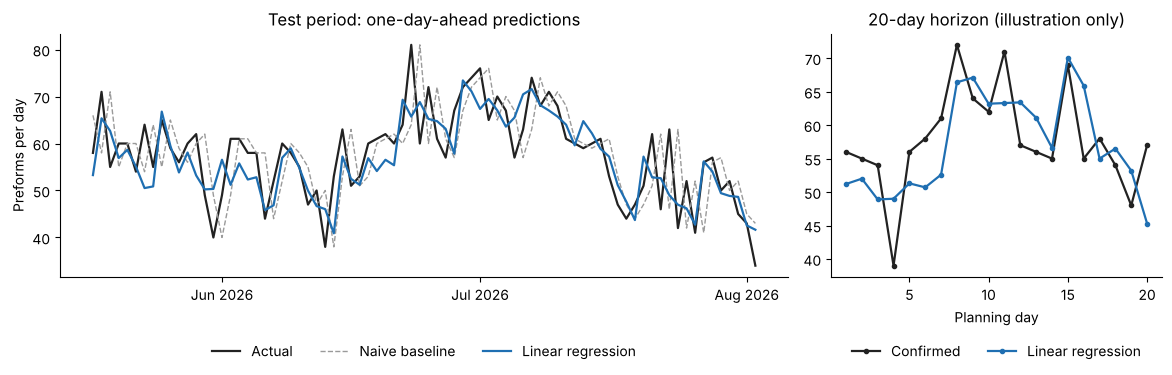

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(h.date.iloc[te], yte.values, color="#222222", lw=1.6, label="Actual")
ax[0].plot(h.date.iloc[te], preds["Naive (yesterday)"], color="#9a9a9a", lw=1, ls="--", label="Naive baseline")
ax[0].plot(h.date.iloc[te], preds["Linear regression (OLS)"], color="#1f6fb2", lw=1.6, label="Linear regression")
ax[0].set_title("Test period: one-day-ahead predictions")
ax[0].set_ylabel("Preforms per day")
ax[0].xaxis.set_major_locator(mdates.MonthLocator())
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[0].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22))

ax[1].plot(conf_pred.planning_day, conf_pred.actual_confirmed, color="#222222", lw=1.6, marker="o", ms=3, label="Confirmed")
ax[1].plot(conf_pred.planning_day, conf_pred.ols, color="#1f6fb2", lw=1.6, marker="o", ms=3, label="Linear regression")
ax[1].set_title("20-day horizon (illustration only)")
ax[1].set_xlabel("Planning day")
ax[1].legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.tight_layout()
fig.savefig("task4_actual_vs_predicted.png", dpi=200)
plt.show()

In [9]:
# Optional: save tables for the report appendix
res.to_csv("task4_test_metrics.csv")
conf_pred.to_csv("task4_confirmed_horizon.csv", index=False)
coef.to_csv("task4_ols_coefficients.csv")

## 4.c Forecast error and the optimisation models (discussion)

**Size of the error.** Test RMSE is about 5.8 units per day on mean demand of about 50. Over 20 days the sum of errors partly cancels, but the lot-sizing models act on individual days.

**Costs are asymmetric.** A backorder costs $100 per unit per day against $15 for holding, a ratio of 100/(100+15), about 0.87. The cost-minimising target is closer to the 87th percentile of demand than to its mean. As a rough guide, with a residual standard deviation near 5.7, that is a buffer of about 6 to 7 units per day, before the $1,000 setup cost and the 100-unit batch cap. OLS under-forecasts on 56% of test days, which is the costly direction.

**Error propagates differently in each task.**
- Task 1: the batch plan is fixed in advance, so a shortfall becomes backorders and a surplus becomes holding cost. One batch per day with a 100-unit cap makes spikes such as a project onset hard to recover from.
- Task 2: quartz delivery is constant and set at the start, so it cannot react. Helium has a 24-hour lead time, so each order rests on a forecast of tomorrow's production. Under-ordering helium can stop a batch and turn a demand error into a backorder.
- Task 3: the joint model removes slack that the sequential approach carries between stages, so it can be more exposed to forecast error unless safety stock or re-planning is added.

**Better accuracy does not automatically mean better decisions.**
1. Value depends on how sensitive the plan is to the forecast. If setup economics fix batch timing anyway, small accuracy gains may change nothing.
2. MAE and RMSE treat over- and under-forecasts equally, but the cost function does not. A slightly less accurate model that under-forecasts less (for example one trained on the 0.87 quantile) can be cheaper.
3. Errors are correlated, clustering around project onsets and weekends, which are the days that matter for backorders.
4. The deterministic models treat the forecast as certain. Accuracy gains only pay off if the plan also uses the uncertainty (safety stock, scenarios, rolling-horizon re-planning).
5. A 20-day plan needs multi-step forecasts, which will be less accurate than the one-day-ahead results here.

**Suggested test.** Re-solve Tasks 1 to 3 using naive, OLS and a biased-up forecast, then cost each plan against the confirmed demand. This measures the cost of forecast error directly.

**Limitations.** The data are synthetic, cover about one year, and the test window is 78 days. The two indicators are assumed known on the day. The 20-day illustration feeds confirmed demand back in as lagged inputs.

*GenAI note for the appendix: Claude was used for coding support and drafting. The team reviewed the code and results and remains responsible for the submitted work.*